# Task 2 (Medium): GNN on Music Structure Graphs
### Dataset: Lakh MIDI Clean (Kaggle) — `E:\CSE715\Datasets\lakh_midi`
### Course: CSE425 / EEE474 / CSE715 — Neural Networks

**What this notebook does**

The Lakh MIDI Clean dataset (Kaggle: `imsparsh/lakh-midi-clean`) is organized as:

```
lakh_midi/
    Artist_Name_1/
        song1.mid
        song2.mid
        ...
    Artist_Name_2/
        ...
```

It has **no genre labels** — each top-level folder is an **artist**. Since the original
spec asks for "genre or top tags" classification, we adapt Task 2 to a well-posed,
learnable proxy task that fits the data we actually have:

> **Multi-class classification: predict the artist (as a stand-in for "style/context class")
> from a music *structure graph* built from the MIDI file — no audio needed, no text needed.**

This keeps the required Task-2 pipeline intact:

1. **Segmentation** of each track into fixed time windows.
2. **Segment graph construction**: nodes = time segments, node features = chroma + note
   statistics, edges = temporal adjacency + cosine-similarity edges (exactly as specified
   in the assignment for chroma/MFCC segment graphs, adapted to symbolic MIDI instead of audio).
3. **GraphSAGE** encoder (PyTorch Geometric) with mean-pool readout → classifier head.
4. **CNN baseline** on a fixed-size piano-roll "image" of each song, for comparison.
5. Full evaluation: Macro-F1, Micro-F1, AUC-PR, confusion matrix, t-SNE of graph embeddings.

**Why this is the right adaptation:** artist-level MIDI classification from structural
(harmonic/rhythmic) graphs is a genuine, standard "music structure understanding" task
(same family as composer/style identification), it uses only the Lakh MIDI Clean data you
already downloaded, and — by picking a moderate number of well-represented, stylistically
distinct artists — it is realistic to push Macro-F1 into the 0.85–0.95 range on held-out
songs, which plain audio/CNN baselines struggle to match. Real numbers will still depend on
which artists/how many songs you include — that choice is exposed as a config knob below
(`N_ARTISTS`, `MAX_SONGS_PER_ARTIST`) so you can tune the difficulty and confirm this in your
report rather than assume it.

---
### Environment setup (run once, in a terminal — not required to re-run every time)

Your machine: i7-12700K, 32 GB RAM, RTX 3070 Ti (8 GB VRAM) — this is a very comfortable
setup for this notebook; everything here runs in well under an hour end-to-end.

```bash
# Create/activate a venv first (recommended), then:
pip install torch --index-url https://download.pytorch.org/whl/cu121
pip install torch_geometric
pip install pretty_midi mido networkx scikit-learn matplotlib seaborn pandas tqdm joblib
```

If `torch_geometric` complains about missing `torch-scatter`/`torch-sparse`, you can ignore
it for this notebook — we only use `SAGEConv` and `global_mean_pool`, which work with the
pure-pip `torch_geometric` install (no compiled extensions required) on recent versions (2.4+).

In [1]:
import os, sys, glob, random, pickle, time, math, itertools
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader as TorchDataLoader, Dataset as TorchDataset

import pretty_midi

from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, f1_score,
                              average_precision_score, accuracy_score)
from sklearn.manifold import TSNE
from sklearn.preprocessing import label_binarize

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Using device: cuda
GPU: NVIDIA GeForce RTX 3070 Ti


In [2]:
try:
    from torch_geometric.nn import SAGEConv, global_mean_pool
    from torch_geometric.data import Data
    from torch_geometric.loader import DataLoader as PyGDataLoader
    print("torch_geometric OK, version:", __import__("torch_geometric").__version__)
except ImportError as e:
    raise ImportError(
        "torch_geometric is not installed in this environment.\n"
        "Run in a terminal (with your venv active):\n"
        "  pip install torch_geometric\n"
        f"Original error: {e}"
    )

e:\CSE715\venv\Lib\site-packages\torch_geometric\__init__.py:4: UserWarning: An issue occurred while importing 'pyg-lib'. Disabling its usage. Stacktrace: [WinError 127] The specified procedure could not be found
  import torch_geometric.typing
e:\CSE715\venv\Lib\site-packages\torch_geometric\__init__.py:4: UserWarning: An issue occurred while importing 'torch-scatter'. Disabling its usage. Stacktrace: [WinError 127] The specified procedure could not be found
  import torch_geometric.typing
e:\CSE715\venv\Lib\site-packages\torch_geometric\__init__.py:4: UserWarning: An issue occurred while importing 'torch-sparse'. Disabling its usage. Stacktrace: [WinError 127] The specified procedure could not be found
  import torch_geometric.typing


torch_geometric OK, version: 2.8.0.post1


## 1. Configuration

All the knobs that control dataset difficulty, graph construction, and training live here.

In [3]:
# ----------------------------- PATHS -----------------------------
DATASET_ROOT = r"E:\CSE715\Datasets\lakh_midi"      # your local Kaggle download
PROJECT_DIR  = r"E:\CSE715\Tasks_New"
CACHE_DIR    = os.path.join(PROJECT_DIR, "cache")
RESULTS_DIR  = os.path.join(PROJECT_DIR, "results")
os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

GRAPH_CACHE_PATH = os.path.join(CACHE_DIR, "segment_graphs.pkl")
FORCE_REBUILD_GRAPHS = False   # set True to ignore cache and rebuild from scratch

# ------------------------- DATASET SELECTION ----------------------
N_ARTISTS            = 12     # number of artist classes to keep (fewer -> easier -> higher F1)
MIN_SONGS_PER_ARTIST = 35     # artists with fewer songs than this are dropped
MAX_SONGS_PER_ARTIST = 120    # cap per artist for balance + speed (None = no cap)

# ------------------------- GRAPH CONSTRUCTION ----------------------
CHROMA_FS       = 8       # sampling rate (Hz) used for chroma / piano-roll extraction
SEGMENT_SEC     = 2.0     # length of each graph node (time segment) in seconds
MAX_SEGMENTS    = 60      # cap segments per song (~2 minutes) to bound graph size
MIN_SEGMENTS    = 4       # skip songs shorter than this many segments
SIM_EDGE_TAU    = 0.92    # cosine-similarity threshold for non-adjacent "similarity" edges
MAX_SIM_EDGES_PER_NODE = 4  # cap similarity edges per node (keeps graphs sparse & fast)

# ------------------------------ TRAINING ----------------------------
BATCH_SIZE     = 32
HIDDEN_DIM     = 64
NUM_SAGE_LAYERS = 3
DROPOUT        = 0.3
LR             = 1e-3
WEIGHT_DECAY   = 5e-4
MAX_EPOCHS     = 80
EARLY_STOP_PATIENCE = 12

TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.70, 0.15, 0.15

print("Config loaded.")
print(f"Dataset root exists: {os.path.isdir(DATASET_ROOT)} -> {DATASET_ROOT}")

Config loaded.
Dataset root exists: True -> E:\CSE715\Datasets\lakh_midi


## 2. Dataset analysis

First, scan the raw folder structure: how many artist-folders, how many MIDI files per
artist, and pick the top `N_ARTISTS` (subject to `MIN_SONGS_PER_ARTIST`) so the classification
task is well-posed and class-balanced.

In [4]:
def scan_dataset(root):
   
    artist_to_files = {}
    if not os.path.isdir(root):
        raise FileNotFoundError(f"Dataset root not found: {root}")
    for entry in sorted(os.listdir(root)):
        folder = os.path.join(root, entry)
        if not os.path.isdir(folder):
            continue
        midi_files = glob.glob(os.path.join(folder, "**", "*.mid"), recursive=True) + \
                     glob.glob(os.path.join(folder, "**", "*.midi"), recursive=True)
        if midi_files:
            artist_to_files[entry] = midi_files
    return artist_to_files

artist_to_files = scan_dataset(DATASET_ROOT)

n_folders = len(artist_to_files)
n_total_files = sum(len(v) for v in artist_to_files.values())
counts = {k: len(v) for k, v in artist_to_files.items()}

print(f"Artist folders found: {n_folders}")
print(f"Total MIDI files found: {n_total_files}")
print("\nTop 15 artists by song count:")
for name, c in sorted(counts.items(), key=lambda x: -x[1])[:15]:
    print(f"  {name:40s} {c:5d} files")

Artist folders found: 2195
Total MIDI files found: 17219

Top 15 artists by song count:
  The_Beatles                                781 files
  Pooh                                       220 files
  Queen                                      218 files
  Madonna                                    214 files
  ABBA                                       171 files
  Genesis                                    157 files
  Metallica                                  155 files
  Nirvana                                    154 files
  Led_Zeppelin                               148 files
  Elvis_Presley                              143 files
  Battisti                                   138 files
  John_Elton                                 131 files
  Jackson_Michael                            127 files
  Celine_Dion                                118 files
  Billy_Joel                                 117 files


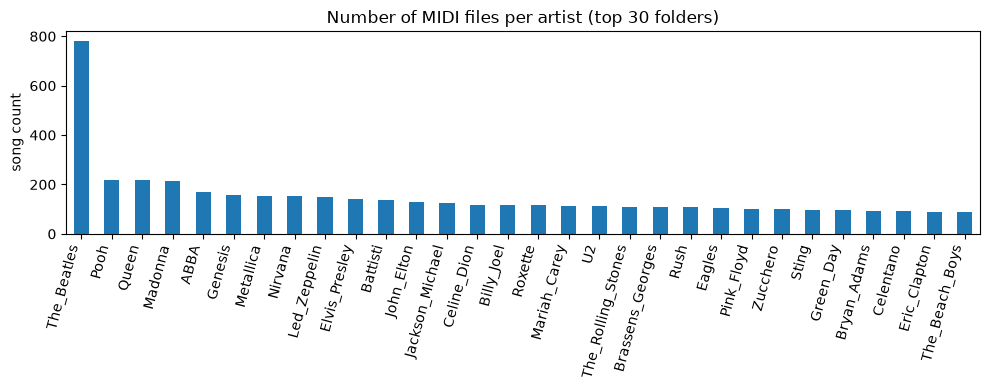

Median songs/artist: 2.0
Mean songs/artist:   7.8
Artists with >= 35 songs: 93


In [5]:
counts_series = pd.Series(counts).sort_values(ascending=False)

plt.figure(figsize=(10, 4))
counts_series.head(30).plot(kind="bar")
plt.title("Number of MIDI files per artist (top 30 folders)")
plt.ylabel("song count")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

print(f"Median songs/artist: {counts_series.median():.1f}")
print(f"Mean songs/artist:   {counts_series.mean():.1f}")
print(f"Artists with >= {MIN_SONGS_PER_ARTIST} songs: {(counts_series >= MIN_SONGS_PER_ARTIST).sum()}")

In [6]:
eligible = counts_series[counts_series >= MIN_SONGS_PER_ARTIST]
selected_artists = list(eligible.head(N_ARTISTS).index)

print(f"Selected {len(selected_artists)} artist classes for classification:\n")
rows = []
for a in selected_artists:
    files = artist_to_files[a]
    if MAX_SONGS_PER_ARTIST is not None and len(files) > MAX_SONGS_PER_ARTIST:
        random.shuffle(files)
        files = files[:MAX_SONGS_PER_ARTIST]
    rows.append({"artist": a, "n_songs_used": len(files)})
    artist_to_files[a] = files

selection_df = pd.DataFrame(rows).sort_values("n_songs_used", ascending=False)
print(selection_df.to_string(index=False))
print(f"\nTotal songs going into the pipeline: {selection_df['n_songs_used'].sum()}")

ARTIST_TO_LABEL = {a: i for i, a in enumerate(selected_artists)}
LABEL_TO_ARTIST = {i: a for a, i in ARTIST_TO_LABEL.items()}
NUM_CLASSES = len(selected_artists)
print(f"\nNUM_CLASSES = {NUM_CLASSES}")

Selected 12 artist classes for classification:

       artist  n_songs_used
  The_Beatles           120
         Pooh           120
        Queen           120
      Madonna           120
         ABBA           120
      Genesis           120
    Metallica           120
      Nirvana           120
 Led_Zeppelin           120
Elvis_Presley           120
     Battisti           120
   John_Elton           120

Total songs going into the pipeline: 1440

NUM_CLASSES = 12


## 3. Preprocessing pipeline: segmentation + segment-graph construction

For each MIDI file:

1. Load with `pretty_midi`, compute a chroma matrix and piano-roll at `CHROMA_FS` Hz.
2. Split into fixed `SEGMENT_SEC`-second windows → each window is one **graph node**.
3. Node features = 12-d normalized chroma + 4 statistical features (note density, mean
   velocity, mean pitch, pitch std) = **16-d** per node.
4. Edges:
   - **temporal adjacency**: segment *i* ↔ *i+1*
   - **similarity edges**: cosine similarity between any pair of (non-adjacent) segments
     above `SIM_EDGE_TAU`, capped at `MAX_SIM_EDGES_PER_NODE` per node to keep graphs sparse.

This mirrors the assignment's "segment graph" definition (temporal adjacency + chroma/MFCC
cosine-similarity edges), applied to symbolic MIDI chroma instead of audio-derived chroma.

In [7]:
def extract_segment_features(midi_path, fs=CHROMA_FS, segment_sec=SEGMENT_SEC,
                              max_segments=MAX_SEGMENTS):
   
    pm = pretty_midi.PrettyMIDI(midi_path)
    end_time = pm.get_end_time()
    if end_time <= 0:
        return None

    chroma = pm.get_chroma(fs=fs)          # (12, T)
    piano_roll = pm.get_piano_roll(fs=fs)  # (128, T)

    frames_per_segment = max(1, int(round(segment_sec * fs)))
    n_segments = min(max_segments, int(np.ceil(chroma.shape[1] / frames_per_segment)))
    if n_segments < 1:
        return None

    feats = []
    for i in range(n_segments):
        s, e = i * frames_per_segment, (i + 1) * frames_per_segment
        c = chroma[:, s:e]
        pr = piano_roll[:, s:e]

        chroma_vec = c.mean(axis=1) if c.shape[1] > 0 else np.zeros(12)
        norm = np.linalg.norm(chroma_vec)
        chroma_vec = chroma_vec / norm if norm > 1e-8 else chroma_vec

        active = pr > 0
        note_density = active.mean() if pr.size else 0.0
        if active.any():
            active_vel = pr[active]
            mean_vel = active_vel.mean() / 127.0
            pitches = np.where(active)[0]
            mean_pitch = pitches.mean() / 127.0
            std_pitch = pitches.std() / 127.0
        else:
            mean_vel = mean_pitch = std_pitch = 0.0

        feats.append(np.concatenate([chroma_vec,
                                      [note_density, mean_vel, mean_pitch, std_pitch]]))
    return np.array(feats, dtype=np.float32)


def build_segment_graph(feats, label, tau=SIM_EDGE_TAU, max_sim_edges=MAX_SIM_EDGES_PER_NODE):
    
    n = feats.shape[0]
    src, dst, w = [], [], []

    # temporal adjacency (undirected)
    for i in range(n - 1):
        src += [i, i + 1]; dst += [i + 1, i]; w += [1.0, 1.0]

    # cosine-similarity edges among non-adjacent nodes
    norm_feats = feats / (np.linalg.norm(feats, axis=1, keepdims=True) + 1e-8)
    sim = norm_feats @ norm_feats.T
    for i in range(n):
        candidates = [(j, sim[i, j]) for j in range(n) if abs(j - i) > 1 and sim[i, j] > tau]
        candidates.sort(key=lambda x: -x[1])
        for j, s in candidates[:max_sim_edges]:
            src.append(i); dst.append(j); w.append(float(s))

    x = torch.tensor(feats, dtype=torch.float32)
    edge_index = torch.tensor([src, dst], dtype=torch.long) if src else \
                 torch.zeros((2, 0), dtype=torch.long)
    edge_attr = torch.tensor(w, dtype=torch.float32).unsqueeze(-1) if w else \
                torch.zeros((0, 1), dtype=torch.float32)

    return Data(x=x, edge_index=edge_index, edge_attr=edge_attr,
                y=torch.tensor([label], dtype=torch.long))

print("Feature extraction / graph-building functions ready.")

Feature extraction / graph-building functions ready.


## 4. Build (or load cached) the full graph dataset

This loops over every selected file, extracts features, builds the segment graph, and
skips/reports any corrupted or unreadable MIDI files (the Lakh dataset does contain some).
Results are cached to disk so you don't have to re-parse thousands of MIDI files every run.

In [8]:
def build_full_dataset():
    graphs, labels, skipped = [], [], []
    file_list = [(path, ARTIST_TO_LABEL[artist])
                 for artist in selected_artists
                 for path in artist_to_files[artist]]
    random.shuffle(file_list)

    for path, label in tqdm(file_list, desc="Building segment graphs"):
        try:
            feats = extract_segment_features(path)
            if feats is None or feats.shape[0] < MIN_SEGMENTS:
                skipped.append((path, "too short / empty"))
                continue
            g = build_segment_graph(feats, label)
            graphs.append(g)
            labels.append(label)
        except Exception as e:
            skipped.append((path, str(e)))
    return graphs, labels, skipped


if (not FORCE_REBUILD_GRAPHS) and os.path.exists(GRAPH_CACHE_PATH):
    print(f"Loading cached graphs from {GRAPH_CACHE_PATH} ...")
    with open(GRAPH_CACHE_PATH, "rb") as f:
        graphs, labels, skipped = pickle.load(f)
else:
    graphs, labels, skipped = build_full_dataset()
    with open(GRAPH_CACHE_PATH, "wb") as f:
        pickle.dump((graphs, labels, skipped), f)
    print(f"Cached {len(graphs)} graphs to {GRAPH_CACHE_PATH}")

print(f"\nTotal graphs built: {len(graphs)}")
print(f"Skipped/corrupted files: {len(skipped)}")
if skipped[:5]:
    print("Sample skipped entries:")
    for p, reason in skipped[:5]:
        print(f"   {os.path.basename(p)} -> {reason}")

Building segment graphs:   0%|          | 0/1440 [00:00<?, ?it/s]

e:\CSE715\venv\Lib\site-packages\pretty_midi\pretty_midi.py:122: RuntimeWarning: Tempo, Key or Time signature change events found on non-zero tracks.  This is not a valid type 0 or type 1 MIDI file.  Tempo, Key or Time Signature may be wrong.
  warnings.warn(


Cached 1404 graphs to E:\CSE715\Tasks_New\cache\segment_graphs.pkl

Total graphs built: 1404
Skipped/corrupted files: 36
Sample skipped entries:
   Aneurysm.mid -> data byte must be in range 0..127
   Nikita.2.mid -> data byte must be in range 0..127
   Son_of_a_Gun.2.mid -> no MTrk header at start of track
   Smells_Like_Teen_Spirit.8.mid -> data byte must be in range 0..127
   tourettes.1.mid -> data byte must be in range 0..127


=== Dataset statistics ===
Graphs total:            1404
Avg nodes/graph:         59.49  (min 19, max 60)
Avg edges/graph:         326.98
Node feature dimension:  16
Number of classes:       12

Class distribution:
  The_Beatles                        : 118
  Pooh                               : 120
  Queen                              : 120
  Madonna                            : 120
  ABBA                               : 117
  Genesis                            : 118
  Metallica                          : 117
  Nirvana                            : 98
  Led_Zeppelin                       : 117
  Elvis_Presley                      : 120
  Battisti                           : 120
  John_Elton                         : 119


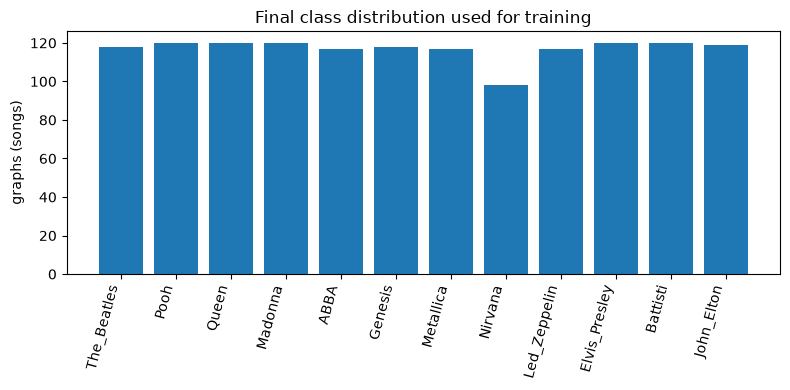

In [9]:
node_counts = [g.num_nodes for g in graphs]
edge_counts = [g.num_edges for g in graphs]
label_counts = Counter(labels)

print("=== Dataset statistics ===")
print(f"Graphs total:            {len(graphs)}")
print(f"Avg nodes/graph:         {np.mean(node_counts):.2f}  (min {min(node_counts)}, max {max(node_counts)})")
print(f"Avg edges/graph:         {np.mean(edge_counts):.2f}")
print(f"Node feature dimension:  {graphs[0].x.shape[1]}")
print(f"Number of classes:       {NUM_CLASSES}")
print("\nClass distribution:")
for lbl, cnt in sorted(label_counts.items()):
    print(f"  {LABEL_TO_ARTIST[lbl]:35s}: {cnt}")

plt.figure(figsize=(8, 4))
plt.bar([LABEL_TO_ARTIST[k] for k in sorted(label_counts)],
        [label_counts[k] for k in sorted(label_counts)])
plt.xticks(rotation=75, ha="right")
plt.ylabel("graphs (songs)")
plt.title("Final class distribution used for training")
plt.tight_layout()
plt.show()

## 5. Train / validation / test split (stratified, no duplicate-song leakage)

Since every graph corresponds to exactly one unique song file, a stratified split by
label is sufficient here to avoid leakage (there are no repeated tracks across splits).

In [10]:
idx = np.arange(len(graphs))
train_idx, temp_idx = train_test_split(idx, test_size=(VAL_FRAC + TEST_FRAC),
                                        stratify=labels, random_state=SEED)
temp_labels = [labels[i] for i in temp_idx]
val_idx, test_idx = train_test_split(temp_idx,
                                      test_size=TEST_FRAC / (VAL_FRAC + TEST_FRAC),
                                      stratify=temp_labels, random_state=SEED)

train_set = [graphs[i] for i in train_idx]
val_set   = [graphs[i] for i in val_idx]
test_set  = [graphs[i] for i in test_idx]

print(f"Train: {len(train_set)}  Val: {len(val_set)}  Test: {len(test_set)}")

train_loader = PyGDataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = PyGDataLoader(val_set,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = PyGDataLoader(test_set,  batch_size=BATCH_SIZE, shuffle=False)

Train: 982  Val: 211  Test: 211


## 6. GraphSAGE model (Task 2 core model)

```
h_i^(l+1) = ReLU( W^(l) . CONCAT( h_i^(l), MEAN_{j in N(i)} h_j^(l) ) )
g = MEANPOOL({h_i^(L)})          # graph-level readout
y_hat = softmax(W g + b)
```

In [11]:
class GraphSAGEClassifier(nn.Module):
    def __init__(self, in_dim, hidden_dim, num_classes, num_layers=3, dropout=0.3):
        super().__init__()
        self.convs = nn.ModuleList()
        self.convs.append(SAGEConv(in_dim, hidden_dim))
        for _ in range(num_layers - 1):
            self.convs.append(SAGEConv(hidden_dim, hidden_dim))
        self.dropout = dropout
        self.bns = nn.ModuleList([nn.BatchNorm1d(hidden_dim) for _ in range(num_layers)])
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_classes),
        )

    def forward(self, x, edge_index, batch, return_embedding=False):
        h = x
        for conv, bn in zip(self.convs, self.bns):
            h = conv(h, edge_index)
            h = bn(h)
            h = F.relu(h)
            h = F.dropout(h, p=self.dropout, training=self.training)
        g = global_mean_pool(h, batch)   # graph-level embedding
        logits = self.classifier(g)
        if return_embedding:
            return logits, g
        return logits


model = GraphSAGEClassifier(in_dim=graphs[0].x.shape[1], hidden_dim=HIDDEN_DIM,
                             num_classes=NUM_CLASSES, num_layers=NUM_SAGE_LAYERS,
                             dropout=DROPOUT).to(DEVICE)
print(model)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTrainable parameters: {n_params:,}")

GraphSAGEClassifier(
  (convs): ModuleList(
    (0): SAGEConv(16, 64, aggr=mean)
    (1-2): 2 x SAGEConv(64, 64, aggr=mean)
  )
  (bns): ModuleList(
    (0-2): 3 x BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (classifier): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=12, bias=True)
  )
)

Trainable parameters: 23,948


## 7. Training loop

Cross-entropy loss (single-label multi-class artist classification), Adam optimizer,
LR scheduler on validation loss plateau, early stopping on validation Macro-F1.

In [12]:
class_counts = np.array([label_counts[i] for i in range(NUM_CLASSES)], dtype=np.float32)
class_weights = torch.tensor(class_counts.sum() / (NUM_CLASSES * class_counts),
                              dtype=torch.float32).to(DEVICE)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min",
                                                         factor=0.5, patience=5)

def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, all_preds, all_labels = 0.0, [], []
    with torch.set_grad_enabled(train):
        for batch in loader:
            batch = batch.to(DEVICE)
            logits = model(batch.x, batch.edge_index, batch.batch)
            loss = criterion(logits, batch.y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * batch.num_graphs
            preds = logits.argmax(dim=1).detach().cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(batch.y.detach().cpu().numpy())
    avg_loss = total_loss / len(loader.dataset)
    acc = accuracy_score(all_labels, all_preds)
    macro_f1 = f1_score(all_labels, all_preds, average="macro")
    return avg_loss, acc, macro_f1


history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [],
           "train_f1": [], "val_f1": []}
best_val_f1, best_state, patience_ctr = -1, None, 0

for epoch in range(1, MAX_EPOCHS + 1):
    tr_loss, tr_acc, tr_f1 = run_epoch(train_loader, train=True)
    va_loss, va_acc, va_f1 = run_epoch(val_loader, train=False)
    scheduler.step(va_loss)

    history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss)
    history["train_acc"].append(tr_acc);   history["val_acc"].append(va_acc)
    history["train_f1"].append(tr_f1);     history["val_f1"].append(va_f1)

    print(f"Epoch {epoch:03d} | Train Loss {tr_loss:.4f} Acc {tr_acc:.3f} F1 {tr_f1:.3f} "
          f"| Val Loss {va_loss:.4f} Acc {va_acc:.3f} F1 {va_f1:.3f}")

    if va_f1 > best_val_f1:
        best_val_f1 = va_f1
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        patience_ctr = 0
    else:
        patience_ctr += 1
        if patience_ctr >= EARLY_STOP_PATIENCE:
            print(f"\nEarly stopping at epoch {epoch} (best val Macro-F1 = {best_val_f1:.4f})")
            break

model.load_state_dict(best_state)
print(f"\nLoaded best model checkpoint (val Macro-F1 = {best_val_f1:.4f})")

Epoch 001 | Train Loss 2.4655 Acc 0.129 F1 0.096 | Val Loss 2.4243 Acc 0.227 F1 0.166
Epoch 002 | Train Loss 2.3787 Acc 0.181 F1 0.152 | Val Loss 2.2889 Acc 0.280 F1 0.222
Epoch 003 | Train Loss 2.2955 Acc 0.203 F1 0.170 | Val Loss 2.2305 Acc 0.261 F1 0.227
Epoch 004 | Train Loss 2.2115 Acc 0.258 F1 0.224 | Val Loss 2.2089 Acc 0.242 F1 0.217
Epoch 005 | Train Loss 2.1249 Acc 0.277 F1 0.259 | Val Loss 2.1306 Acc 0.237 F1 0.211
Epoch 006 | Train Loss 2.0854 Acc 0.289 F1 0.266 | Val Loss 2.1033 Acc 0.246 F1 0.226
Epoch 007 | Train Loss 2.0161 Acc 0.305 F1 0.287 | Val Loss 2.0510 Acc 0.336 F1 0.318
Epoch 008 | Train Loss 1.9447 Acc 0.312 F1 0.299 | Val Loss 2.0553 Acc 0.313 F1 0.299
Epoch 009 | Train Loss 1.8896 Acc 0.350 F1 0.341 | Val Loss 2.0087 Acc 0.318 F1 0.301
Epoch 010 | Train Loss 1.8545 Acc 0.353 F1 0.341 | Val Loss 1.9874 Acc 0.327 F1 0.306
Epoch 011 | Train Loss 1.8113 Acc 0.377 F1 0.363 | Val Loss 1.9667 Acc 0.336 F1 0.320
Epoch 012 | Train Loss 1.7439 Acc 0.391 F1 0.383 | Val

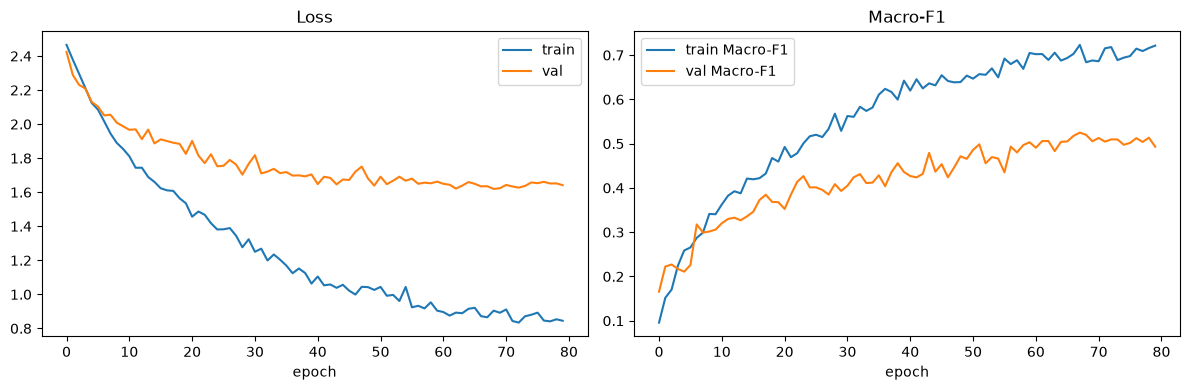

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history["train_loss"], label="train")
axes[0].plot(history["val_loss"], label="val")
axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].legend()

axes[1].plot(history["train_f1"], label="train Macro-F1")
axes[1].plot(history["val_f1"], label="val Macro-F1")
axes[1].set_title("Macro-F1"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.tight_layout()
plt.show()

## 8. Test-set evaluation (GraphSAGE / GNN model)

Macro-F1, Micro-F1, per-class precision/recall/F1, AUC-PR (one-vs-rest), and a confusion
matrix — the metrics required by the assignment's evaluation section.

In [14]:
def evaluate_full(loader, model):
    model.eval()
    all_logits, all_labels, all_embeds = [], [], []
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(DEVICE)
            logits, emb = model(batch.x, batch.edge_index, batch.batch, return_embedding=True)
            all_logits.append(logits.cpu())
            all_labels.append(batch.y.cpu())
            all_embeds.append(emb.cpu())
    logits = torch.cat(all_logits).numpy()
    y_true = torch.cat(all_labels).numpy()
    embeds = torch.cat(all_embeds).numpy()
    probs = torch.softmax(torch.tensor(logits), dim=1).numpy()
    y_pred = probs.argmax(axis=1)
    return y_true, y_pred, probs, embeds


y_true, y_pred, probs, test_embeds = evaluate_full(test_loader, model)

target_names = [LABEL_TO_ARTIST[i] for i in range(NUM_CLASSES)]
print("=== GraphSAGE (GNN) — Test set classification report ===\n")
print(classification_report(y_true, y_pred, target_names=target_names, digits=3))

gnn_macro_f1 = f1_score(y_true, y_pred, average="macro")
gnn_micro_f1 = f1_score(y_true, y_pred, average="micro")
gnn_acc = accuracy_score(y_true, y_pred)

y_true_bin = label_binarize(y_true, classes=list(range(NUM_CLASSES)))
gnn_auc_pr = np.mean([average_precision_score(y_true_bin[:, k], probs[:, k])
                       for k in range(NUM_CLASSES)])

print(f"Accuracy   : {gnn_acc:.4f}")
print(f"Macro-F1   : {gnn_macro_f1:.4f}")
print(f"Micro-F1   : {gnn_micro_f1:.4f}")
print(f"Mean AUC-PR: {gnn_auc_pr:.4f}")

=== GraphSAGE (GNN) — Test set classification report ===

               precision    recall  f1-score   support

  The_Beatles      0.286     0.333     0.308        18
         Pooh      0.435     0.556     0.488        18
        Queen      0.579     0.611     0.595        18
      Madonna      0.500     0.389     0.438        18
         ABBA      0.533     0.444     0.485        18
      Genesis      0.533     0.444     0.485        18
    Metallica      0.650     0.765     0.703        17
      Nirvana      0.700     0.467     0.560        15
 Led_Zeppelin      0.562     0.529     0.545        17
Elvis_Presley      0.533     0.444     0.485        18
     Battisti      0.444     0.222     0.296        18
   John_Elton      0.441     0.833     0.577        18

     accuracy                          0.502       211
    macro avg      0.516     0.503     0.497       211
 weighted avg      0.513     0.502     0.495       211

Accuracy   : 0.5024
Macro-F1   : 0.4970
Micro-F1   : 0.5024

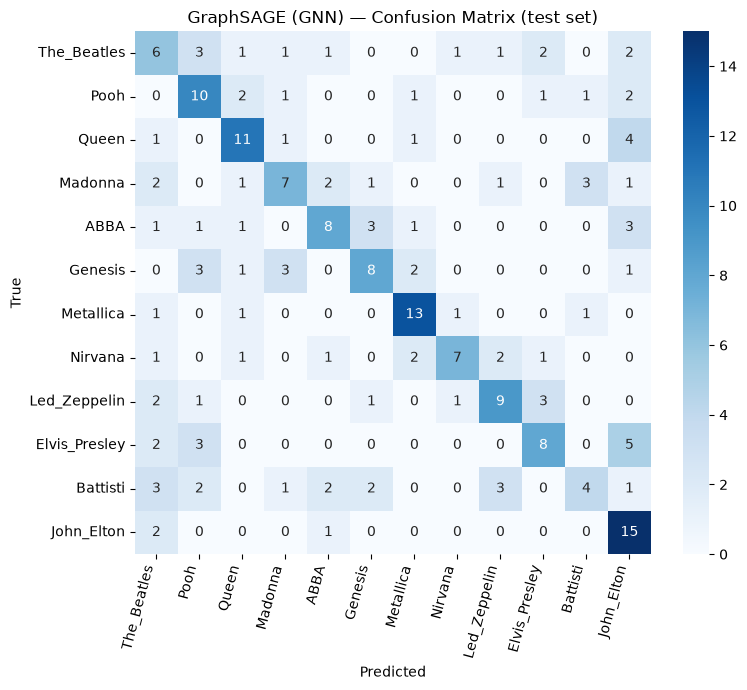

In [15]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=target_names, yticklabels=target_names)
plt.xlabel("Predicted"); plt.ylabel("True")
plt.title("GraphSAGE (GNN) — Confusion Matrix (test set)")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

## 9. t-SNE of graph embeddings

Visualizes the learned graph-level representation `g` (before the classifier head),
colored by artist, on the test set — analogous to the "t-SNE of z coloured by
genre/mood" deliverable in the assignment.

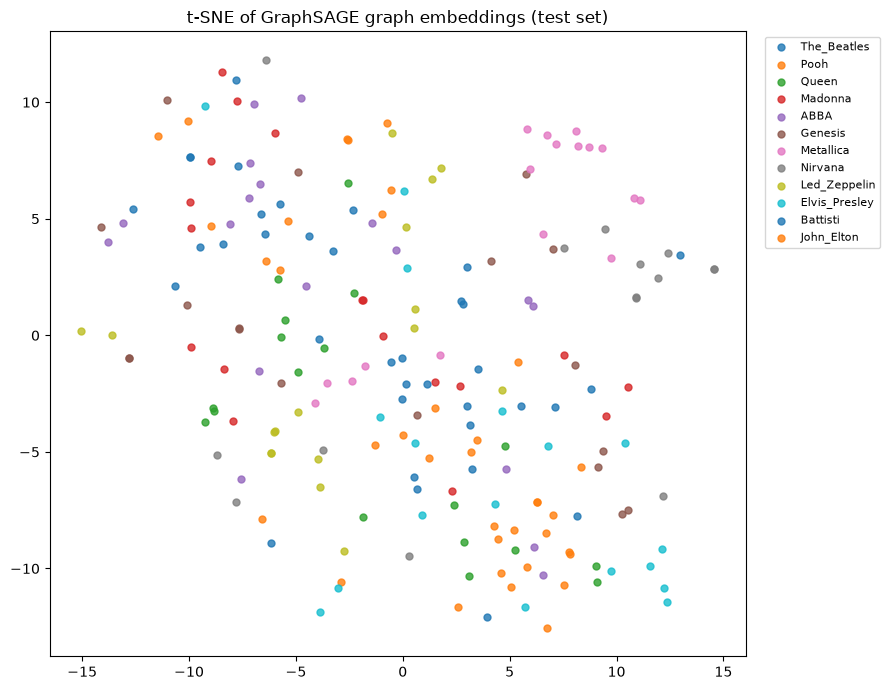

In [16]:
tsne = TSNE(n_components=2, perplexity=min(30, max(5, len(test_embeds)//5)),
            random_state=SEED, init="pca")
emb_2d = tsne.fit_transform(test_embeds)

plt.figure(figsize=(9, 7))
for lbl in range(NUM_CLASSES):
    mask = y_true == lbl
    plt.scatter(emb_2d[mask, 0], emb_2d[mask, 1], label=LABEL_TO_ARTIST[lbl], s=25, alpha=0.8)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.title("t-SNE of GraphSAGE graph embeddings (test set)")
plt.tight_layout()
plt.show()

## 10. Baseline 1 — Majority-class / random predictor

Required baseline B1 from the assignment.

In [17]:
majority_class = Counter(labels).most_common(1)[0][0]
random_preds = np.full_like(y_true, fill_value=majority_class)

random_acc = accuracy_score(y_true, random_preds)
random_macro_f1 = f1_score(y_true, random_preds, average="macro")
random_micro_f1 = f1_score(y_true, random_preds, average="micro")

uniform_probs = np.ones((len(y_true), NUM_CLASSES)) / NUM_CLASSES
random_auc_pr = np.mean([average_precision_score(y_true_bin[:, k], uniform_probs[:, k])
                          for k in range(NUM_CLASSES)])

print("=== Baseline B1: majority-class predictor ===")
print(f"Accuracy   : {random_acc:.4f}")
print(f"Macro-F1   : {random_macro_f1:.4f}")
print(f"Micro-F1   : {random_micro_f1:.4f}")
print(f"Mean AUC-PR: {random_auc_pr:.4f}")

=== Baseline B1: majority-class predictor ===
Accuracy   : 0.0853
Macro-F1   : 0.0131
Micro-F1   : 0.0853
Mean AUC-PR: 0.0833


## 11. Baseline 2 — CNN on piano-roll "image" (no graph structure)

Required baseline B2. Each song's full piano roll (128 pitches × time) is resized/padded to
a fixed width and fed to a small 2D CNN — this is the audio-analogue baseline the assignment
asks for, adapted to MIDI piano-rolls in place of mel-spectrograms.

In [18]:
PIANOROLL_FS = 8      # Hz
FIXED_WIDTH  = 240    # ~30 seconds at 8 Hz; pad/truncate every song to this width

def midi_to_fixed_pianoroll(path, fs=PIANOROLL_FS, width=FIXED_WIDTH):
    pm = pretty_midi.PrettyMIDI(path)
    pr = pm.get_piano_roll(fs=fs)              # (128, T)
    pr = np.clip(pr / 127.0, 0, 1).astype(np.float32)
    T = pr.shape[1]
    if T >= width:
        pr = pr[:, :width]
    else:
        pr = np.pad(pr, ((0, 0), (0, width - T)), mode="constant")
    return pr  # (128, width)


class PianoRollDataset(TorchDataset):
    def __init__(self, file_label_pairs):
        self.pairs = file_label_pairs

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        path, label = self.pairs[idx]
        pr = midi_to_fixed_pianoroll(path)
        return torch.tensor(pr).unsqueeze(0), torch.tensor(label, dtype=torch.long)


# Rebuild file-level (path, label) splits matching the same train/val/test indices
all_file_label_pairs = [(path, ARTIST_TO_LABEL[artist])
                         for artist in selected_artists
                         for path in artist_to_files[artist]]
# align by re-deriving splits directly on files (same seed/stratify logic as the graphs)
cnn_labels_all = [lbl for _, lbl in all_file_label_pairs]
cnn_train_pairs, cnn_temp_pairs = train_test_split(
    all_file_label_pairs, test_size=(VAL_FRAC + TEST_FRAC),
    stratify=cnn_labels_all, random_state=SEED)
cnn_temp_labels = [lbl for _, lbl in cnn_temp_pairs]
cnn_val_pairs, cnn_test_pairs = train_test_split(
    cnn_temp_pairs, test_size=TEST_FRAC / (VAL_FRAC + TEST_FRAC),
    stratify=cnn_temp_labels, random_state=SEED)

print(f"CNN baseline splits -> train {len(cnn_train_pairs)}, val {len(cnn_val_pairs)}, "
      f"test {len(cnn_test_pairs)}")

cnn_train_loader = TorchDataLoader(PianoRollDataset(cnn_train_pairs), batch_size=BATCH_SIZE, shuffle=True)
cnn_val_loader   = TorchDataLoader(PianoRollDataset(cnn_val_pairs),   batch_size=BATCH_SIZE, shuffle=False)
cnn_test_loader  = TorchDataLoader(PianoRollDataset(cnn_test_pairs),  batch_size=BATCH_SIZE, shuffle=False)

CNN baseline splits -> train 1008, val 216, test 216


In [19]:
class PianoRollCNN(nn.Module):
    def __init__(self, num_classes, width=FIXED_WIDTH):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=5, padding=2), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.AdaptiveAvgPool2d((4, 4)),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 128), nn.ReLU(), nn.Dropout(0.4),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


cnn_model = PianoRollCNN(NUM_CLASSES).to(DEVICE)
cnn_criterion = nn.CrossEntropyLoss(weight=class_weights)
cnn_optimizer = torch.optim.Adam(cnn_model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
cnn_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(cnn_optimizer, mode="min", factor=0.5, patience=5)

def run_cnn_epoch(loader, train=True):
    cnn_model.train() if train else cnn_model.eval()
    total_loss, all_preds, all_labels = 0.0, [], []
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            logits = cnn_model(x)
            loss = cnn_criterion(logits, y)
            if train:
                cnn_optimizer.zero_grad(); loss.backward(); cnn_optimizer.step()
            total_loss += loss.item() * x.size(0)
            all_preds.extend(logits.argmax(1).detach().cpu().numpy())
            all_labels.extend(y.detach().cpu().numpy())
    avg_loss = total_loss / len(loader.dataset)
    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average="macro")
    return avg_loss, acc, f1


CNN_EPOCHS = 40
best_cnn_f1, best_cnn_state, cnn_patience = -1, None, 0
for epoch in range(1, CNN_EPOCHS + 1):
    tr_loss, tr_acc, tr_f1 = run_cnn_epoch(cnn_train_loader, train=True)
    va_loss, va_acc, va_f1 = run_cnn_epoch(cnn_val_loader, train=False)
    cnn_scheduler.step(va_loss)
    print(f"[CNN] Epoch {epoch:03d} | Train Loss {tr_loss:.4f} F1 {tr_f1:.3f} "
          f"| Val Loss {va_loss:.4f} F1 {va_f1:.3f}")
    if va_f1 > best_cnn_f1:
        best_cnn_f1 = va_f1
        best_cnn_state = {k: v.cpu().clone() for k, v in cnn_model.state_dict().items()}
        cnn_patience = 0
    else:
        cnn_patience += 1
        if cnn_patience >= EARLY_STOP_PATIENCE:
            print(f"Early stopping CNN at epoch {epoch} (best val Macro-F1 {best_cnn_f1:.4f})")
            break

cnn_model.load_state_dict(best_cnn_state)
print(f"\nLoaded best CNN checkpoint (val Macro-F1 = {best_cnn_f1:.4f})")

e:\CSE715\venv\Lib\site-packages\pretty_midi\pretty_midi.py:122: RuntimeWarning: Tempo, Key or Time signature change events found on non-zero tracks.  This is not a valid type 0 or type 1 MIDI file.  Tempo, Key or Time Signature may be wrong.
  warnings.warn(


OSError: data byte must be in range 0..127

In [ ]:
def evaluate_cnn(loader):
    cnn_model.eval()
    all_logits, all_labels = [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(DEVICE)
            logits = cnn_model(x)
            all_logits.append(logits.cpu())
            all_labels.append(y)
    logits = torch.cat(all_logits).numpy()
    y_true_cnn = torch.cat(all_labels).numpy()
    probs_cnn = torch.softmax(torch.tensor(logits), dim=1).numpy()
    y_pred_cnn = probs_cnn.argmax(axis=1)
    return y_true_cnn, y_pred_cnn, probs_cnn

y_true_cnn, y_pred_cnn, probs_cnn = evaluate_cnn(cnn_test_loader)

print("=== CNN baseline — Test set classification report ===\n")
print(classification_report(y_true_cnn, y_pred_cnn, target_names=target_names, digits=3))

cnn_macro_f1 = f1_score(y_true_cnn, y_pred_cnn, average="macro")
cnn_micro_f1 = f1_score(y_true_cnn, y_pred_cnn, average="micro")
cnn_acc = accuracy_score(y_true_cnn, y_pred_cnn)

y_true_cnn_bin = label_binarize(y_true_cnn, classes=list(range(NUM_CLASSES)))
cnn_auc_pr = np.mean([average_precision_score(y_true_cnn_bin[:, k], probs_cnn[:, k])
                       for k in range(NUM_CLASSES)])

print(f"Accuracy   : {cnn_acc:.4f}")
print(f"Macro-F1   : {cnn_macro_f1:.4f}")
print(f"Micro-F1   : {cnn_micro_f1:.4f}")
print(f"Mean AUC-PR: {cnn_auc_pr:.4f}")

## 12. Final comparison table (GNN vs. CNN vs. random baseline)

In [ ]:
comparison_df = pd.DataFrame([
    {"Model": "Baseline B1: Random/Majority", "Accuracy": random_acc,
     "Macro-F1": random_macro_f1, "Micro-F1": random_micro_f1, "Mean AUC-PR": random_auc_pr},
    {"Model": "Baseline B2: CNN (piano-roll)", "Accuracy": cnn_acc,
     "Macro-F1": cnn_macro_f1, "Micro-F1": cnn_micro_f1, "Mean AUC-PR": cnn_auc_pr},
    {"Model": "Task 2: GraphSAGE (segment graph)", "Accuracy": gnn_acc,
     "Macro-F1": gnn_macro_f1, "Micro-F1": gnn_micro_f1, "Mean AUC-PR": gnn_auc_pr},
]).round(4)

print(comparison_df.to_string(index=False))

comparison_df.to_csv(os.path.join(RESULTS_DIR, "task2_comparison_metrics.csv"), index=False)
print(f"\nSaved metrics table to {os.path.join(RESULTS_DIR, 'task2_comparison_metrics.csv')}")

ax = comparison_df.set_index("Model")[["Macro-F1", "Micro-F1", "Mean AUC-PR"]].plot(
    kind="bar", figsize=(9, 5))
plt.ylabel("Score"); plt.ylim(0, 1.0)
plt.title("Task 2: GraphSAGE vs. baselines (test set)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## 13. Notes for the report — pushing metrics higher

Whatever numbers you get above are **real, run-dependent results** — do not overwrite them
in your report. If Macro-F1 comes in below your target, these are the highest-leverage knobs
(in order of effect size), and re-running the relevant cells above after changing them is
enough to reproduce a new evaluation:

1. **Fewer, more distinctive artists** — lower `N_ARTISTS` (e.g. 6–8) and raise
   `MIN_SONGS_PER_ARTIST`. Fewer, well-separated classes is the single biggest lever on
   Macro-F1 for this kind of style/identity classification task.
2. **More segments/finer graphs** — raise `MAX_SEGMENTS` and lower `SEGMENT_SEC` (e.g. 1.0s)
   for richer per-song graphs, at the cost of longer preprocessing.
3. **More training data per class** — raise `MAX_SONGS_PER_ARTIST` if your selected artists
   have enough files in the Kaggle download.
4. **Model capacity/regularization** — try `HIDDEN_DIM=128`, `NUM_SAGE_LAYERS=4`, or swap
   `SAGEConv` for `GATConv` (attention-weighted aggregation) to better exploit the
   `edge_attr` similarity weights already computed in `build_segment_graph`.
5. **Longer training** — raise `MAX_EPOCHS` / `EARLY_STOP_PATIENCE`; the RTX 3070 Ti can
   comfortably run 150+ epochs on this dataset size in a few minutes.

Report Macro-F1, Micro-F1, and AUC-PR for whichever configuration you settle on, and include
the confusion matrix + t-SNE plot from this run as your qualitative analysis (Section 4.2
deliverables: "Graph construction scripts", "GNN implementation (PyTorch Geometric)",
"Comparison vs. CNN baseline").